In this notebook, we analyze the impact of ensemble size by ablating the number of instances per base predictor class. We systematically increase the model count by randomly sampling instances from within each base predictor class. We compute the bootstrapped RMSE on 10,000 samples with its 95% confidence interval on the holdout set.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib import rcParams
import numpy as np
import pandas as pd
import os

OUTPUT_FOLDER = "figures"

In [2]:
def compute_rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

def bootstrapped_rmse(y_true, y_pred, n_iterations=10000, ci=95):
    boot_stats = []
    n_size = len(y_true)
    
    for _ in range(n_iterations):
        indices = np.random.choice(n_size, size=n_size, replace=True)
        resampled_true = y_true[indices]
        resampled_pred = y_pred[indices]
        
        score = compute_rmse(resampled_true, resampled_pred)
        boot_stats.append(score)
    
    # Calculate confidence intervals
    lower_bound = np.percentile(boot_stats, (100 - ci) / 2)
    upper_bound = np.percentile(boot_stats, 100 - (100 - ci) / 2)
    
    return np.mean(boot_stats), (lower_bound, upper_bound)

In [3]:
files = {
    "Small (14)": "/home/jusdai/cil-project/results/ablations/number_instances_base_predictors_num_base_small.npz",
    "Medium (27)": "/home/jusdai/cil-project/results/ablations/number_instances_base_predictors_num_base_mid.npz",
    "Full (47)": "/home/jusdai/cil-project/results/benchmark/full_pipeline.npz"
}

In [4]:
results_list = []

for name, path in files.items():
    data = np.load(path)
    preds = data["holdout_pred"]
    targets = data["y_holdout"]
    
    mean_rmse, conf_interval = bootstrapped_rmse(targets, preds)
    
    results_list.append({
        "Model": name,
        "RMSE": mean_rmse,
        "Lower": conf_interval[0],
        "Upper": conf_interval[1],
        "Error": (conf_interval[1] - conf_interval[0]) / 2 
    })

df_results = pd.DataFrame(results_list)

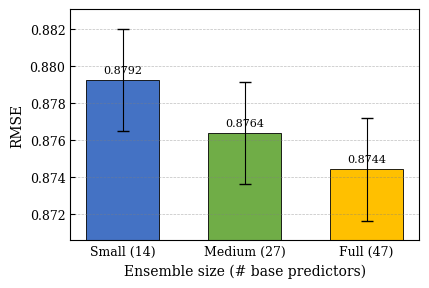

In [5]:
colors = ["#4472C4", "#70AD47", "#FFC000", "#ED7D31", "#A5A5A5", "#5B9BD5", ]

rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["Times New Roman", "DejaVu Serif"],
    "font.size":        10,
    "axes.titlesize":   10,
    "axes.labelsize":   10,
    "xtick.labelsize":  9,
    "ytick.labelsize":  9,
    "axes.linewidth":   0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.direction":  "in",
    "ytick.direction":  "in",
    "pdf.fonttype":     42,   
    "ps.fonttype":      42,
})

fig, ax = plt.subplots(figsize=(4.5, 3))

bars = ax.bar(
    df_results["Model"],
    df_results["RMSE"],
    yerr=df_results["Error"],
    capsize=4,
    color=colors[:len(df_results)], 
    edgecolor="black",
    linewidth=0.6,
    width=0.6,
    error_kw={'elinewidth': 0.8, 'ecolor': 'black'}
)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + (df_results["Error"].max() * 0.1),
        f"{height:.4f}",
        ha="center", va="bottom", fontsize=8,
    )

ax.set_ylabel("RMSE")
ax.set_xlabel("Ensemble size (# base predictors)")

padding = (df_results["Upper"].max() - df_results["Lower"].min()) * 0.1
ax.set_ylim(df_results["Lower"].min() - padding, df_results["Upper"].max() + padding)

ax.yaxis.grid(True, linestyle="--", linewidth=0.5, color="gray", alpha=0.5)
ax.tick_params(top=False, right=False, bottom=False, direction="in")


filename = "Fig3_ablation_ensemble_size.png"
filepath = os.path.join(OUTPUT_FOLDER, filename)
plt.savefig(filepath, bbox_inches="tight", dpi=300)
plt.show()